### Step 1

In [17]:
# ==========================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ==========================================================

import math
import random

from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Step 2 — Set CCEA and mapping parameters

In [ ]:
# ==========================================================
# STEP 2: SET CCEA AND SCORE PARAMETERS
# ==========================================================

# ----------------------------------------------------------
# CCEA PARAMETERS
# ----------------------------------------------------------

RANDOM_SEED = 42

MAX_GENERATIONS = 100

MUTATION_PROBABILITY = 0.20

EXPLORATION_PROBABILITY = 0.25

PATIENCE = 20

MIN_IMPROVEMENT = 1e-8


# ----------------------------------------------------------
# SCORE MAPPING PARAMETERS
#
# These parameters are defined here,
# but actual mapping is performed ONLY during
# fitness evaluation.
# ----------------------------------------------------------

# Parameters!B2
MIN_MAPPED_SCORE = 0.03

# Parameters!B3
MAX_ATTACK_PLAN_SCORE = 35

# Reduced Severity scale
MAX_REDUCED_SEVERITY = 10


# ----------------------------------------------------------
# REPRODUCIBILITY
# ----------------------------------------------------------

random.seed(RANDOM_SEED)

np.random.seed(RANDOM_SEED)


print("CCEA PARAMETERS")
print("-" * 50)

print("Random Seed             :", RANDOM_SEED)

print("Maximum Generations     :", MAX_GENERATIONS)

print("Mutation Probability    :", MUTATION_PROBABILITY)

print("Exploration Probability :", EXPLORATION_PROBABILITY)

print("Patience                :", PATIENCE)

### Step 3 — Load the dataset

In [ ]:
# ==========================================================
# STEP 3: LOAD THE DATASET
# ==========================================================

# Reduced_Severity source: False = CSV column, True = LLM-produced variant
USE_LLM = False
data = pd.read_csv("../data/CCE_llm.csv" if USE_LLM else "../data/CCE.csv")


print(
    "Dataset Shape:",
    data.shape
)


print(
    "\nColumns:"
)

print(
    data.columns.tolist()
)


print(
    "\nFirst 10 Rows:"
)

display(
    data.head(10)
)

### Step 4 — Clean, verify, validate, and summarize dataset

In [ ]:
# ==========================================================
# STEP 4: CLEAN, VERIFY, VALIDATE, AND SUMMARIZE DATASET
# ==========================================================


# ----------------------------------------------------------
# A. CLEAN COLUMN NAMES
# ----------------------------------------------------------

data.columns = (
    data.columns
    .str.replace(
        "\u00a0",
        " ",
        regex=False
    )
    .str.strip()
)


# ----------------------------------------------------------
# B. VERIFY REQUIRED COLUMNS
# ----------------------------------------------------------

required_columns = [

    "Candidate_ID",

    "Hash",

    "Signature_ID",

    "Defense_ID",

    "Attack_Plan_Score",

    "Reduced_Severity"
]


missing_columns = [

    column

    for column in required_columns

    if column not in data.columns
]


if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ----------------------------------------------------------
# C. CLEAN IDENTIFIER COLUMNS
# ----------------------------------------------------------

for column in [

    "Candidate_ID",

    "Hash",

    "Signature_ID",

    "Defense_ID"
]:

    data[column] = (

        data[column]

        .astype(str)

        .str.strip()

        .str.replace(
            r"\.0$",
            "",
            regex=True
        )
    )


# ----------------------------------------------------------
# D. CLEAN NUMERIC COLUMNS
# ----------------------------------------------------------

for column in [

    "Attack_Plan_Score",

    "Reduced_Severity"
]:

    data[column] = pd.to_numeric(

        data[column],

        errors="coerce"
    )


# ----------------------------------------------------------
# E. CHECK UNIQUE CANDIDATE IDs
# ----------------------------------------------------------

if data["Candidate_ID"].duplicated().any():

    raise ValueError(

        "Candidate_ID must be unique for every row."
    )


# ----------------------------------------------------------
# F. CHECK MISSING NUMERIC VALUES
# ----------------------------------------------------------

if data[
    [
        "Attack_Plan_Score",
        "Reduced_Severity"
    ]
].isnull().any().any():

    raise ValueError(

        "Numeric columns contain missing or invalid values."
    )


# ----------------------------------------------------------
# G. VALIDATE ATTACK PLAN SCORE
# ----------------------------------------------------------

if not data[
    "Attack_Plan_Score"
].between(
    1,
    MAX_ATTACK_PLAN_SCORE
).all():

    raise ValueError(

        "Attack_Plan_Score contains values "
        "outside the valid range."
    )




# ----------------------------------------------------------
# I. VALIDATE REDUCED SEVERITY
# ----------------------------------------------------------

if not data[
    "Reduced_Severity"
].between(
    0,
    MAX_REDUCED_SEVERITY
).all():

    raise ValueError(

        "Reduced_Severity contains values "
        "outside the valid range."
    )


# ----------------------------------------------------------
# J. DISPLAY DATASET SUMMARY
# ----------------------------------------------------------

print(
    "DATASET CLEANING AND VALIDATION COMPLETED"
)

print(
    "-" * 55
)


print(
    "Total Candidate Rows :",
    len(data)
)


print(
    "Malware Samples      :",
    data["Hash"].nunique()
)


print(
    "Unique Signatures    :",
    data["Signature_ID"].nunique()
)


print(
    "\nRAW SCORE RANGES"
)


print(
    "Attack Plan Score :",
    data[
        "Attack_Plan_Score"
    ].min(),
    "to",
    data[
        "Attack_Plan_Score"
    ].max()
)


print(
    "Defense ID        :",
    data[
        "Defense_ID"
    ].min(),
    "to",
    data[
        "Defense_ID"
    ].max()
)


print(
    "Reduced Severity  :",
    data[
        "Reduced_Severity"
    ].min(),
    "to",
    data[
        "Reduced_Severity"
    ].max()
)


print(
    "\nFirst 10 Cleaned Rows:"
)


display(
    data.head(10)
)

### Step 5 — Select one malware sample

In [21]:
# ==========================================================
# STEP 5: SELECT ONE MALWARE SAMPLE
# ==========================================================

sample_hash = (
    data[
        "Hash"
    ].iloc[0]
)


sample_data = data[

    data[
        "Hash"
    ]

    ==

    sample_hash

].copy()


print(
    "Selected Malware Hash:",
    sample_hash
)


print(
    "Candidate Rows:",
    len(sample_data)
)

Selected Malware Hash: 15232
Candidate Rows: 131


### Step 6 — Identify triggered signatures

In [22]:
# ==========================================================
# STEP 6: IDENTIFY TRIGGERED SIGNATURES
# ==========================================================

# dict.fromkeys preserves the original order
# while identifying unique signature IDs.

signature_order = list(

    dict.fromkeys(

        sample_data[
            "Signature_ID"
        ].tolist()
    )
)


print(
    "Number of Triggered Signatures:",
    len(signature_order)
)


print(
    "\nTriggered Signatures:"
)


print(
    signature_order
)

Number of Triggered Signatures: 26

Triggered Signatures:
['39', '9', '13', '14', '1', '50', '16', '17', '44', '19', '20', '22', '51', '41', '23', '54', '70', '55', '26', '56', '31', '58', '59', '32', '82', '36']


### Step 7 — Define each defense candidate

In [ ]:
# ==========================================================
# STEP 7: DEFINE DEFENSE CANDIDATE
# ==========================================================

@dataclass
class DefenseCandidate:

    # Unique row-level identity
    candidate_id: str

    # Signature/subpopulation identity
    signature_id: str

    # Raw Defense Score
    defense_id: float

    # Raw Attack Plan Score
    attack_plan_score: float

    # Dataset Reduced Severity
    # Treated currently as if generated by the LLM
    reduced_severity: float


    # Collaborative fitness values obtained
    # when this candidate participates in combinations
    fitness_history: list = field(
        default_factory=list
    )


    # Number of combinations in which
    # this candidate has participated
    evaluation_count: int = 0


    @property
    def mean_fitness(self):

        if not self.fitness_history:

            return float(
                "-inf"
            )

        return float(

            np.mean(
                self.fitness_history
            )
        )


    @property
    def best_fitness(self):

        if not self.fitness_history:

            return float(
                "-inf"
            )

        return float(

            np.max(
                self.fitness_history
            )
        )

#### Step 8 — Divide defense population into signature-specific subpopulations

In [ ]:
# ==========================================================
# STEP 8: CREATE SIGNATURE-SPECIFIC SUBPOPULATIONS
# ==========================================================

def create_subpopulations(
    sample_data,
    signature_order
):

    """
    Create one defense subpopulation for every
    triggered signature.

    IMPORTANT:
    Every CSV row is treated as a separate candidate.

    No duplicate rows are removed.
    """


    subpopulations = {}


    for signature_id in signature_order:


        # --------------------------------------------------
        # Extract ALL candidate rows for this signature
        # --------------------------------------------------

        signature_rows = sample_data[

            sample_data[
                "Signature_ID"
            ]

            ==

            signature_id
        ]


        candidates = []


        # --------------------------------------------------
        # Convert every row into a DefenseCandidate
        # --------------------------------------------------

        for _, row in signature_rows.iterrows():


            candidate = DefenseCandidate(

                candidate_id=
                    row[
                        "Candidate_ID"
                    ],

                signature_id=
                    row[
                        "Signature_ID"
                    ],

                defense_id=
                    float(
                        row[
                            "Defense_ID"
                        ]
                    ),

                attack_plan_score=
                    float(
                        row[
                            "Attack_Plan_Score"
                        ]
                    ),

                reduced_severity=
                    float(
                        row[
                            "Reduced_Severity"
                        ]
                    )
            )


            candidates.append(
                candidate
            )


        # --------------------------------------------------
        # Store the subpopulation
        # --------------------------------------------------

        subpopulations[
            signature_id
        ] = candidates


    return subpopulations

In [25]:
subpopulations = (

    create_subpopulations(

        sample_data,

        signature_order
    )
)


print(
    "Number of Defense Subpopulations:",
    len(subpopulations)
)

Number of Defense Subpopulations: 26


### Step 9 — Display subpopulations

In [27]:
# ==========================================================
# STEP 9: DISPLAY SUBPOPULATION DETAILS
# ==========================================================

subpopulation_summary = []


for signature_id, candidates in (
    subpopulations.items()
):


    subpopulation_summary.append(
        {
            "Signature_ID":
                signature_id,

            "Number_of_Candidates":
                len(candidates)
        }
    )


subpopulation_summary_df = (
    pd.DataFrame(
        subpopulation_summary
    )
)


print(
    "SUBPOPULATION SUMMARY"
)


display(
    subpopulation_summary_df
)

SUBPOPULATION SUMMARY


,Signature_ID,Number_of_Candidates
0,39,1
1,9,4
2,13,8
3,14,8
4,1,4
5,50,1
6,16,13
7,17,5
8,44,1
9,19,9


In [ ]:
for signature_id, candidates in (
    subpopulations.items()
):


    print(
        "\n" + "=" * 70
    )


    print(
        "SIGNATURE:",
        signature_id
    )


    print(
        "NUMBER OF CANDIDATES:",
        len(candidates)
    )


    rows = []


    for candidate in candidates:


        rows.append(
            {
                "Candidate_ID":
                    candidate.candidate_id,

                "Signature_ID":
                    candidate.signature_id,

                "Attack_Plan_Score":
                    candidate.attack_plan_score,

                "Defense_ID":
                    candidate.defense_id,

                "Reduced_Severity":
                    candidate.reduced_severity
            }
        )


    display(
        pd.DataFrame(
            rows
        )
    )

### Step 10 — Calculate search space

In [30]:
# ==========================================================
# STEP 10: CALCULATE TOTAL SEARCH SPACE
# ==========================================================

search_space = 1


for candidates in (
    subpopulations.values()
):

    search_space *= len(
        candidates
    )


print(
    "Total Possible Complete Defense Combinations:"
)


print(
    search_space
)

Total Possible Complete Defense Combinations:
297568567296000


### Step 11 — Representative selection

In [31]:
# ==========================================================
# STEP 11: SELECT REPRESENTATIVE FROM EACH SUBPOPULATION
# ==========================================================

def select_representative(
    candidates
):

    """
    Representative selection priority:

    1. Evaluate unexplored candidates.
    2. Allow random exploration.
    3. Otherwise select candidate with highest
       collaborative fitness.
    """


    # ------------------------------------------------------
    # 1. UNEXPLORED CANDIDATES
    # ------------------------------------------------------

    unexplored_candidates = [

        candidate

        for candidate in candidates

        if candidate.evaluation_count == 0
    ]


    if unexplored_candidates:


        selected_candidate = (

            random.choice(
                unexplored_candidates
            )
        )


        return (
            selected_candidate,
            "Unexplored"
        )


    # ------------------------------------------------------
    # 2. RANDOM EXPLORATION
    # ------------------------------------------------------

    if (

        random.random()

        <

        EXPLORATION_PROBABILITY
    ):


        selected_candidate = (

            random.choice(
                candidates
            )
        )


        return (
            selected_candidate,
            "Random Exploration"
        )


    # ------------------------------------------------------
    # 3. COLLABORATIVE FITNESS SELECTION
    # ------------------------------------------------------

    selected_candidate = max(

        candidates,

        key=lambda candidate: (

            candidate.mean_fitness,

            candidate.best_fitness
        )
    )


    return (
        selected_candidate,
        "Collaborative Fitness"
    )

### Step 12 — Mutation

In [32]:
# ==========================================================
# STEP 12: MUTATION
# ==========================================================

def mutate_candidate(
    selected_candidate,
    candidates
):

    """
    Mutation replaces the selected representative
    with another existing candidate from the SAME
    signature-specific subpopulation.
    """


    # ------------------------------------------------------
    # Mutation impossible when only one candidate exists
    # ------------------------------------------------------

    if len(candidates) <= 1:

        return (
            selected_candidate,
            False
        )


    # ------------------------------------------------------
    # Determine whether mutation occurs
    # ------------------------------------------------------

    if (

        random.random()

        >=

        MUTATION_PROBABILITY
    ):

        return (
            selected_candidate,
            False
        )


    # ------------------------------------------------------
    # Find valid alternatives
    # ------------------------------------------------------

    alternatives = [

        candidate

        for candidate in candidates

        if candidate.candidate_id
        !=
        selected_candidate.candidate_id
    ]


    # ------------------------------------------------------
    # Choose mutation
    # ------------------------------------------------------

    mutated_candidate = (

        random.choice(
            alternatives
        )
    )


    return (
        mutated_candidate,
        True
    )

#### Step 13 — Construct complete defense combination

In [34]:
# ==========================================================
# STEP 13: CONSTRUCT COMPLETE DEFENSE COMBINATION
# ==========================================================

def construct_combination(
    subpopulations
):

    """
    Select exactly one representative from every
    signature-specific subpopulation.

    The resulting set is one complete defense strategy.
    """


    combination = {}

    selection_log = []


    for signature_id, candidates in (
        subpopulations.items()
    ):


        # --------------------------------------------------
        # Representative selection
        # --------------------------------------------------

        selected_candidate, selection_method = (

            select_representative(
                candidates
            )
        )


        initially_selected = (
            selected_candidate.candidate_id
        )


        # --------------------------------------------------
        # Mutation
        # --------------------------------------------------

        final_candidate, mutated = (

            mutate_candidate(

                selected_candidate,

                candidates
            )
        )


        # --------------------------------------------------
        # Store final representative
        # --------------------------------------------------

        combination[
            signature_id
        ] = final_candidate


        selection_log.append(
            {
                "Signature_ID":
                    signature_id,

                "Initially_Selected":
                    initially_selected,

                "Final_Candidate":
                    final_candidate.candidate_id,

                "Selection_Method":
                    selection_method,

                "Mutation":
                    mutated
            }
        )


    return (
        combination,
        selection_log
    )

#### Step 14 — RMS function

In [35]:
# ==========================================================
# STEP 14: ROOT MEAN SQUARE FUNCTION
# ==========================================================

def calculate_rms(
    values
):

    """
    RMS = sqrt(mean(values^2))
    """


    values = np.asarray(
        values,
        dtype=float
    )


    if values.size == 0:

        raise ValueError(

            "Cannot calculate RMS from an empty list."
        )


    return float(

        np.sqrt(

            np.mean(

                np.square(
                    values
                )
            )
        )
    )

### Step 15 — Fitness evaluation with all mapping done here

In [ ]:
# ==========================================================
# STEP 15: COMPLETE FITNESS EVALUATION
# ==========================================================

def evaluate_combination(
    sample_hash,
    generation,
    combination
):

    """
    Evaluate one complete defense combination.

    All mapping is performed ONLY during this
    fitness evaluation.

    --------------------------------------------------------
    ATTACK PLAN SCORE MAPPING
    --------------------------------------------------------

    AttackMapped =
        0.03
        +
        (1 - 0.03)
        *
        (AttackRaw - 1)
        /
        (35 - 1)


    --------------------------------------------------------
    REDUCED SEVERITY MAPPING
    --------------------------------------------------------

    RSMapped =
        RSRaw / 10

    Therefore:

        RSRaw = 0
        gives
        RSMapped = 0


    --------------------------------------------------------
    COLLABORATIVE FITNESS
    --------------------------------------------------------

    IS_Aggr =
        RMS(AttackMapped)

    RS_Aggr =
        RMS(RSMapped)

    Fitness =
        (IS_Aggr - RS_Aggr)
        /
        IS_Aggr
    """


    mapped_attack_scores = []

    mapped_reduced_severities = []

    combination_details = []


    # ======================================================
    # PROCESS EVERY PARTICIPATING DEFENSE CANDIDATE
    # ======================================================

    for signature_id, candidate in (
        combination.items()
    ):


        # ==================================================
        # 1. MAP ATTACK PLAN SCORE
        # ==================================================

        attack_mapped = (

            MIN_MAPPED_SCORE

            +

            (1 - MIN_MAPPED_SCORE)

            *

            (
                candidate.attack_plan_score
                -
                1
            )

            /

            (
                MAX_ATTACK_PLAN_SCORE
                -
                1
            )
        )


        # ==================================================
        # 3. MAP REDUCED SEVERITY
        # ==================================================

        reduced_severity_mapped = (

            candidate.reduced_severity

            /

            MAX_REDUCED_SEVERITY
        )


        # ==================================================
        # 4. VALIDATE MAPPED VALUES
        # ==================================================

        if not (
            0 <= attack_mapped <= 1
        ):

            raise ValueError(

                f"Invalid mapped Attack Score "
                f"for {candidate.candidate_id}"
            )


        if not (
            0 <= reduced_severity_mapped <= 1
        ):

            raise ValueError(

                f"Invalid mapped Reduced Severity "
                f"for {candidate.candidate_id}"
            )


        # ==================================================
        # 5. STORE VALUES REQUIRED FOR FITNESS
        # ==================================================

        mapped_attack_scores.append(
            attack_mapped
        )


        mapped_reduced_severities.append(
            reduced_severity_mapped
        )


        # ==================================================
        # 6. STORE COMPLETE DETAILS
        # ==================================================

        combination_details.append(
            {
                "Hash":
                    sample_hash,

                "Generation":
                    generation,

                "Candidate_ID":
                    candidate.candidate_id,

                "Signature_ID":
                    signature_id,

                "Attack_Plan_Score":
                    candidate.attack_plan_score,

                "Attack_Mapped":
                    attack_mapped,

                "Defense_ID":
                    candidate.defense_id,

                "Reduced_Severity":
                    candidate.reduced_severity,

                "Reduced_Severity_Mapped":
                    reduced_severity_mapped
            }
        )


    # ======================================================
    # 7. AGGREGATE INITIAL SEVERITY
    # ======================================================

    IS_Aggr = calculate_rms(
        mapped_attack_scores
    )


    # ======================================================
    # 8. AGGREGATE REDUCED SEVERITY
    # ======================================================

    RS_Aggr = calculate_rms(
        mapped_reduced_severities
    )


    # ======================================================
    # 9. CALCULATE COLLABORATIVE FITNESS
    # ======================================================

    if math.isclose(
        IS_Aggr,
        0.0,
        abs_tol=1e-12
    ):

        fitness = 0.0

    else:

        fitness = (

            IS_Aggr
            -
            RS_Aggr

        ) / IS_Aggr


    # ======================================================
    # 10. ASSIGN SAME COLLABORATIVE FITNESS
    #     TO ALL PARTICIPANTS
    # ======================================================

    for candidate in (
        combination.values()
    ):


        candidate.fitness_history.append(
            fitness
        )


        candidate.evaluation_count += 1


    # ======================================================
    # 11. RETURN RESULT
    # ======================================================

    return {

        "Hash":
            sample_hash,

        "Generation":
            generation,

        "Combination":
            combination,

        "Combination_Details":
            combination_details,

        "IS_Aggr":
            float(
                IS_Aggr
            ),

        "RS_Aggr":
            float(
                RS_Aggr
            ),

        "Fitness":
            float(
                fitness
            )
    }

#### Step 16 — Check candidate coverage

In [37]:
# ==========================================================
# STEP 16: CHECK CANDIDATE COVERAGE
# ==========================================================

def all_candidates_evaluated(
    subpopulations
):

    """
    Return True only if every original row-level
    candidate has participated in at least one
    complete combination.
    """


    return all(

        candidate.evaluation_count > 0

        for candidates
        in subpopulations.values()

        for candidate
        in candidates
    )

#### Step 17 — Run the CCEA

In [38]:
# ==========================================================
# STEP 17: RUN COOPERATIVE CO-EVOLUTION
# ==========================================================


# ----------------------------------------------------------
# Reset candidate histories
# ----------------------------------------------------------

for candidates in (
    subpopulations.values()
):

    for candidate in candidates:

        candidate.fitness_history = []

        candidate.evaluation_count = 0


# Reset random seed
random.seed(
    RANDOM_SEED
)

np.random.seed(
    RANDOM_SEED
)


# ----------------------------------------------------------
# Variables for optimization
# ----------------------------------------------------------

best_result = None

generations_without_improvement = 0

generation_history = []

all_evaluations = []


# ==========================================================
# MAIN CCEA LOOP
# ==========================================================

for generation in range(
    1,
    MAX_GENERATIONS + 1
):


    print(
        "\n" + "=" * 75
    )


    print(
        "GENERATION",
        generation
    )


    print(
        "=" * 75
    )


    # ------------------------------------------------------
    # 1. Construct complete defense combination
    # ------------------------------------------------------

    combination, selection_log = (

        construct_combination(
            subpopulations
        )
    )


    # ------------------------------------------------------
    # 2. Evaluate combination
    #
    # All score mapping happens inside
    # evaluate_combination()
    # ------------------------------------------------------

    result = evaluate_combination(

        sample_hash=
            sample_hash,

        generation=
            generation,

        combination=
            combination
    )


    # ------------------------------------------------------
    # 3. Store complete evaluation
    # ------------------------------------------------------

    all_evaluations.append(
        result
    )


    # ------------------------------------------------------
    # 4. Display current fitness
    # ------------------------------------------------------

    print(
        "IS_Aggr :",
        round(
            result[
                "IS_Aggr"
            ],
            6
        )
    )


    print(
        "RS_Aggr :",
        round(
            result[
                "RS_Aggr"
            ],
            6
        )
    )


    print(
        "Fitness :",
        round(
            result[
                "Fitness"
            ],
            6
        )
    )


    # ------------------------------------------------------
    # 5. Check whether this combination is better
    # ------------------------------------------------------

    improved = False


    if best_result is None:

        improved = True


    elif (

        result[
            "Fitness"
        ]

        >

        best_result[
            "Fitness"
        ]

        +

        MIN_IMPROVEMENT

    ):

        improved = True


    # ------------------------------------------------------
    # 6. Update global best
    # ------------------------------------------------------

    if improved:


        best_result = result


        generations_without_improvement = 0


        print(
            "NEW BEST COMBINATION FOUND"
        )


    else:


        generations_without_improvement += 1


    # ------------------------------------------------------
    # 7. Store generation history
    # ------------------------------------------------------

    generation_history.append(
        {
            "Generation":
                generation,

            "Generation_Fitness":
                result[
                    "Fitness"
                ],

            "Best_Fitness_So_Far":
                best_result[
                    "Fitness"
                ],

            "IS_Aggr":
                result[
                    "IS_Aggr"
                ],

            "RS_Aggr":
                result[
                    "RS_Aggr"
                ]
        }
    )


    # ------------------------------------------------------
    # 8. Calculate candidate coverage
    # ------------------------------------------------------

    total_candidates = sum(

        len(candidates)

        for candidates
        in subpopulations.values()
    )


    evaluated_candidates = sum(

        1

        for candidates
        in subpopulations.values()

        for candidate
        in candidates

        if candidate.evaluation_count > 0
    )


    print(
        "Candidate Coverage:",
        evaluated_candidates,
        "/",
        total_candidates
    )


    print(
        "Best Fitness So Far:",
        round(
            best_result[
                "Fitness"
            ],
            6
        )
    )


    # ------------------------------------------------------
    # 9. Termination
    # ------------------------------------------------------

    if (

        all_candidates_evaluated(
            subpopulations
        )

        and

        generations_without_improvement
        >=
        PATIENCE

    ):


        print(
            "\nTermination criterion reached."
        )


        break


GENERATION 1
IS_Aggr : 0.595274
RS_Aggr : 0.153172
Fitness : 0.742687
NEW BEST COMBINATION FOUND
Candidate Coverage: 26 / 131
Best Fitness So Far: 0.742687

GENERATION 2
IS_Aggr : 0.595274
RS_Aggr : 0.186052
Fitness : 0.687451
Candidate Coverage: 43 / 131
Best Fitness So Far: 0.742687

GENERATION 3
IS_Aggr : 0.595274
RS_Aggr : 0.173205
Fitness : 0.709033
Candidate Coverage: 57 / 131
Best Fitness So Far: 0.742687

GENERATION 4
IS_Aggr : 0.595274
RS_Aggr : 0.142775
Fitness : 0.760153
NEW BEST COMBINATION FOUND
Candidate Coverage: 72 / 131
Best Fitness So Far: 0.760153

GENERATION 5
IS_Aggr : 0.595274
RS_Aggr : 0.173205
Fitness : 0.709033
Candidate Coverage: 84 / 131
Best Fitness So Far: 0.760153

GENERATION 6
IS_Aggr : 0.595274
RS_Aggr : 0.19115
Fitness : 0.678887
Candidate Coverage: 92 / 131
Best Fitness So Far: 0.760153

GENERATION 7
IS_Aggr : 0.595274
RS_Aggr : 0.193152
Fitness : 0.675524
Candidate Coverage: 103 / 131
Best Fitness So Far: 0.760153

GENERATION 8
IS_Aggr : 0.595274
RS_

#### Step 18 — Display final optimal strategy

In [39]:
# ==========================================================
# STEP 18: DISPLAY FINAL OPTIMAL DEFENSE STRATEGY
# ==========================================================

print(
    "\n" + "=" * 80
)


print(
    "FINAL OPTIMAL DEFENSE STRATEGY"
)


print(
    "=" * 80
)


print(
    "Best Generation :",
    best_result[
        "Generation"
    ]
)


print(
    "IS_Aggr        :",
    best_result[
        "IS_Aggr"
    ]
)


print(
    "RS_Aggr        :",
    best_result[
        "RS_Aggr"
    ]
)


print(
    "Best Fitness   :",
    best_result[
        "Fitness"
    ]
)


optimal_strategy_df = (

    pd.DataFrame(

        best_result[
            "Combination_Details"
        ]
    )
)


print(
    "\nOPTIMAL DEFENSE COMBINATION"
)


display(
    optimal_strategy_df
)


FINAL OPTIMAL DEFENSE STRATEGY
Best Generation : 81
IS_Aggr        : 0.5952743027728105
RS_Aggr        : 0.10561177090573833
Best Fitness   : 0.8225830169154041

OPTIMAL DEFENSE COMBINATION


,Hash,Generation,Candidate_ID,Signature_ID,Attack_Plan_Score,Attack_Mapped,Defense_Score,Defense_Mapped,Reduced_Severity,Reduced_Severity_Mapped
0,15232,81,C1,39,1.0,0.030000,14.0,0.693684,0.0,0.0
1,15232,81,C4,9,6.0,0.172647,2.0,0.081053,1.0,0.1
2,15232,81,C13,13,1.0,0.030000,1.0,0.030000,1.0,0.1
3,15232,81,C18,14,20.0,0.572059,2.0,0.081053,2.0,0.2
4,15232,81,C25,1,15.0,0.429412,4.0,0.183158,1.0,0.1
5,15232,81,C26,50,2.0,0.058529,13.0,0.642632,0.0,0.0
6,15232,81,C28,16,16.0,0.457941,6.0,0.285263,1.0,0.1
7,15232,81,C42,17,15.0,0.429412,5.0,0.234211,1.0,0.1
8,15232,81,C45,44,8.0,0.229706,13.0,0.642632,0.0,0.0
9,15232,81,C54,19,13.0,0.372353,13.0,0.642632,0.0,0.0


### Step 19 — Candidate collaborative fitness

In [ ]:
# ==========================================================
# STEP 19: DISPLAY CANDIDATE COLLABORATIVE PERFORMANCE
# ==========================================================

candidate_results = []


for signature_id, candidates in (
    subpopulations.items()
):


    for candidate in candidates:


        candidate_results.append(
            {
                "Candidate_ID":
                    candidate.candidate_id,

                "Signature_ID":
                    signature_id,

                "Attack_Plan_Score":
                    candidate.attack_plan_score,

                "Defense_ID":
                    candidate.defense_id,

                "Reduced_Severity":
                    candidate.reduced_severity,

                "Evaluation_Count":
                    candidate.evaluation_count,

                "Mean_Collaborative_Fitness":
                    (
                        candidate.mean_fitness

                        if
                        candidate.evaluation_count > 0

                        else
                        np.nan
                    ),

                "Best_Collaborative_Fitness":
                    (
                        candidate.best_fitness

                        if
                        candidate.evaluation_count > 0

                        else
                        np.nan
                    )
            }
        )


candidate_results_df = (
    pd.DataFrame(
        candidate_results
    )
)


display(
    candidate_results_df
)

### Step 20 — Generation history

In [41]:
# ==========================================================
# STEP 20: DISPLAY GENERATION HISTORY
# ==========================================================

generation_history_df = (

    pd.DataFrame(
        generation_history
    )
)


display(
    generation_history_df
)

,Generation,Generation_Fitness,Best_Fitness_So_Far,IS_Aggr,RS_Aggr
0,1,0.742687,0.742687,0.595274,0.153172
1,2,0.687451,0.742687,0.595274,0.186052
2,3,0.709033,0.742687,0.595274,0.173205
3,4,0.760153,0.760153,0.595274,0.142775
4,5,0.709033,0.760153,0.595274,0.173205
...,...,...,...,...,...
95,96,0.740587,0.822583,0.595274,0.154422
96,97,0.822583,0.822583,0.595274,0.105612
97,98,0.776553,0.822583,0.595274,0.133012
98,99,0.769381,0.822583,0.595274,0.137281


### Step 21 — Plot fitness convergence

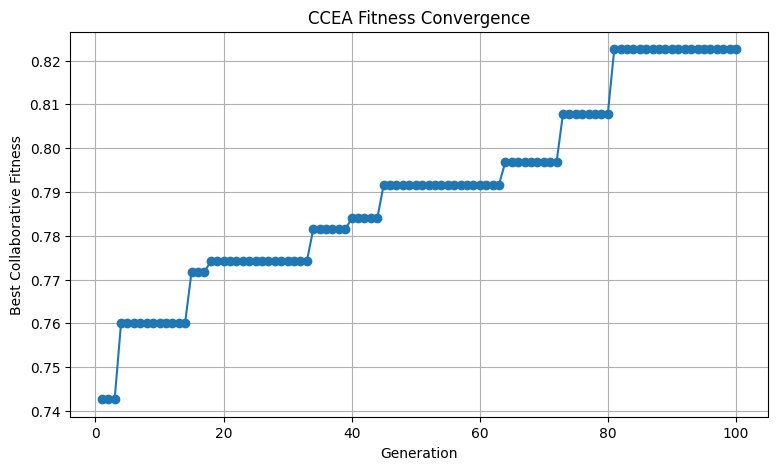

In [42]:
# ==========================================================
# STEP 21: PLOT FITNESS CONVERGENCE
# ==========================================================

plt.figure(
    figsize=(9, 5)
)


plt.plot(

    generation_history_df[
        "Generation"
    ],

    generation_history_df[
        "Best_Fitness_So_Far"
    ],

    marker="o"
)


plt.xlabel(
    "Generation"
)


plt.ylabel(
    "Best Collaborative Fitness"
)


plt.title(
    "CCEA Fitness Convergence"
)


plt.grid(
    True
)


plt.show()

The x-axis represents the generations, and the y-axis represents the best collaborative fitness found so far. The fitness improves from approximately 0.743 to 0.823 during the optimization.

The staircase pattern is important. A horizontal section means the algorithm is testing different defense combinations but has not yet found one better than the current best. A vertical increase means a newly evaluated complete defense combination achieved a higher collaborative fitness and therefore replaced the previous best.

For example, the progression is approximately:

$$ 0.743 \rightarrow 0.760 \rightarrow 0.772 \rightarrow 0.774 \rightarrow 0.782 \rightarrow 0.784 \rightarrow 0.792 \rightarrow 0.797 \rightarrow 0.808 \rightarrow 0.823 $$

Toward the end, the fitness remains at about 0.823 for several generations. This indicates that the algorithm has stabilized around its best discovered solution; subsequent combinations did not improve on it.